# Decision model 2: two-step decision
First pick the application, then pick an action from only that application's actions.

In [1]:
import json
import time
from typing import cast

from dotenv import load_dotenv
from IPython.display import JSON, display
from typesafe_sdk import Choice, ChoiceAnswer, TypeSafeClient

from demo_helpers import VALID_APPLICATIONS
from demo_helpers import plot_probabilities

load_dotenv()

True

In [2]:
transcript = "Hey Google, navigate to Ara."

In [3]:
# Opened once and reused across cells; closed at the end of the notebook
client = TypeSafeClient(model="jev-latest").__enter__()

## Call 1: which application?

In [4]:
app_questions = {
    "application": Choice(
        instructions="Which application does the user want to use?",
        criteria={name: app["description"] for name, app in VALID_APPLICATIONS.items()},
    ),
}
app_questions

{'application': Choice(type='choice', instructions='Which application does the user want to use?', criteria={'maps': 'Navigation and location search', 'music': 'Music streaming and playback', 'messages': 'Send and read text messages', 'calendar': 'Manage events and reminders', 'weather': 'Weather forecasts and conditions'})}

In [5]:
start = time.perf_counter()
app_response = client.system_one(state=transcript, questions=app_questions)
print(f"Application call took {time.perf_counter() - start:.2f}s")
app_response

Application call took 0.27s


SystemOneResponse(model='jev-1.14.0', usage=Usage(input_tokens=368, output_tokens=52), answers={'application': ChoiceAnswer(type='choice', choice='maps', confidence=1.0, probabilities={'maps': 1.0, 'music': 0.0, 'messages': 0.0, 'calendar': 0.0, 'weather': 0.0})})

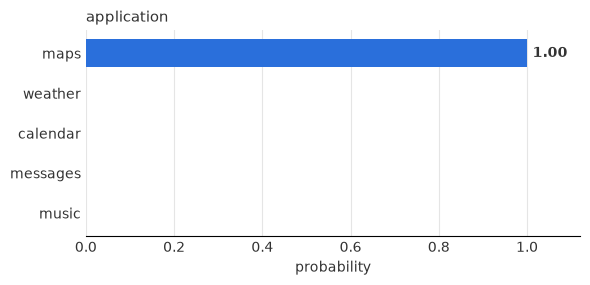

ChoiceAnswer(type='choice', choice='maps', confidence=1.0, probabilities={'maps': 1.0, 'music': 0.0, 'messages': 0.0, 'calendar': 0.0, 'weather': 0.0})

In [6]:
app_answer = cast(ChoiceAnswer, app_response.answers["application"])
app_name = app_answer.choice
app = VALID_APPLICATIONS[app_name]
plot_probabilities(app_response.answers)
app_answer

## Call 2: which action, within the chosen application?

In [7]:
action_questions = {
    "action": Choice(
        instructions=(
            f"The user is using the {app_name} application "
            f"({app['description']}). Which action do they want?"
        ),
        criteria={
            action_name: action_name.replace("_", " ") for action_name in app["actions"]
        },
    ),
}
action_questions

{'action': Choice(type='choice', instructions='The user is using the maps application (Navigation and location search). Which action do they want?', criteria={'navigate': 'navigate', 'search_nearby': 'search nearby', 'show_traffic': 'show traffic'})}

In [8]:
start = time.perf_counter()
action_response = client.system_one(state=transcript, questions=action_questions)
print(f"Action call took {time.perf_counter() - start:.2f}s")
action_response

Action call took 0.18s


SystemOneResponse(model='jev-1.14.0', usage=Usage(input_tokens=346, output_tokens=44), answers={'action': ChoiceAnswer(type='choice', choice='navigate', confidence=1.0, probabilities={'navigate': 1.0, 'search_nearby': 0.0, 'show_traffic': 0.0})})

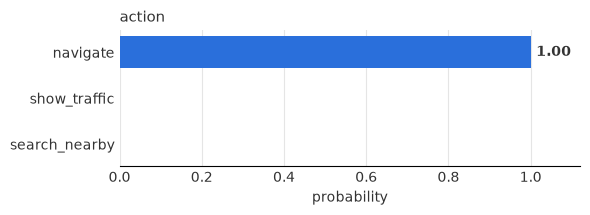

ChoiceAnswer(type='choice', choice='navigate', confidence=1.0, probabilities={'navigate': 1.0, 'search_nearby': 0.0, 'show_traffic': 0.0})

In [9]:
action_answer = cast(ChoiceAnswer, action_response.answers["action"])
action_name = action_answer.choice
plot_probabilities(action_response.answers)
action_answer

## Result

In [10]:
print(f"target_application: {app_answer.choice} ({app_answer.confidence:.2f})")
print(f"target_action:      {action_answer.choice} ({action_answer.confidence:.2f})")

target_application: maps (1.00)
target_action:      navigate (1.00)


In [11]:
client.__exit__(None, None, None)